# Markov Clustering (MCL) analysis of the HLJ1-centred yeast PPI network

This notebook builds a weighted network from a STRING interaction table, keeps high-confidence associations, runs MCL, and exports cluster tables and figures. It is designed as a **reproducible template**: add the actual STRING file before running it. No protein clusters or biological findings are pre-filled.

**Project settings used here:** yeast STRING network; confidence threshold 700; edge weight = confidence score / 1000; focal protein HLJ1 (YMR161W). This is the full functional-association network, not the physical-only subnetwork. STRING associations can include direct physical interactions and broader functional associations.


## 1. Prepare the input file

Put the STRING protein interaction `.txt.gz` file beside this notebook, or change `INPUT_FILE` below. The file must contain two protein columns and a confidence-score column (for example `4932.protein.links.v12.0.txt.gz`; it contains `protein1`, `protein2`, and `combined_score`). If your downloaded file uses other column names, set them explicitly in the configuration cell.

For GitHub, place this notebook in `notebook/`. Keep large raw data files out of GitHub unless the group has agreed to store them there; include a short note describing where the data came from and how to obtain it.


In [1]:
# Install once if these packages are missing; uncomment the next line in a fresh environment.
# %pip install pandas numpy scipy networkx matplotlib markov-clustering

from pathlib import Path
import re
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
import markov_clustering as mc

INPUT_FILE = Path("4932.protein.links.v12.0.txt.gz")
CONFIDENCE_THRESHOLD = 700
HLJ1_ID = "YMR161W"       # Yeast systematic gene name; change if your input uses another identifier.
INFLATION = 2.0           # MCL granularity parameter; test alternatives in Section 7.
EDGE_SOURCE_COL = None    # Set to a column name if automatic detection selects the wrong one.
EDGE_TARGET_COL = None
SCORE_COL = None
OUTPUT_DIR = Path("mcl_output")
OUTPUT_DIR.mkdir(exist_ok=True)


## 2. Load and inspect the STRING table

The cell below attempts to recognise common STRING column names. Check the printed column names and first rows. If detection fails, fill in the three column names in the configuration cell above and rerun this section.


In [1]:
if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"Cannot find {INPUT_FILE}. Put the STRING .txt.gz data file beside this notebook or update INPUT_FILE."
    )

raw = pd.read_csv(INPUT_FILE, sep=r"\s+", comment=None, low_memory=False)
print("Input shape:", raw.shape)
print("Columns:", list(raw.columns))
display(raw.head())


def find_col(columns, candidates):
    normalised = {str(c).lstrip("#").lower(): c for c in columns}
    for candidate in candidates:
        if candidate.lower() in normalised:
            return normalised[candidate.lower()]
    return None

source_col = EDGE_SOURCE_COL or find_col(raw.columns, ["protein1", "string_protein_id_a", "node1", "source", "protein_a"])
target_col = EDGE_TARGET_COL or find_col(raw.columns, ["protein2", "string_protein_id_b", "node2", "target", "protein_b"])
score_col = SCORE_COL or find_col(raw.columns, ["combined_score", "score", "confidence", "weight"])

if not all([source_col, target_col, score_col]):
    raise ValueError(
        "Could not identify the two protein columns and score column. "
        "Set EDGE_SOURCE_COL, EDGE_TARGET_COL, and SCORE_COL to the exact column names, then rerun."
    )
print(f"Using columns: {source_col!r}, {target_col!r}, {score_col!r}")


Input shape: (2824842, 3)
Columns: ['protein1', 'protein2', 'combined_score']
Using columns: 'protein1', 'protein2', 'combined_score'


protein1,protein2,combined_score
4932.Q0010,4932.YMR207C,333
4932.Q0010,4932.YCR051W,205
4932.Q0010,4932.YPR002W,195
4932.Q0010,4932.YGR117C,166
4932.Q0010,4932.YML056C,152


## 3. Filter and construct the weighted network

STRING confidence scores are on a 0–1000 scale. We retain scores at or above 700 and convert them to edge weights between 0 and 1. Duplicate undirected pairs are represented by their strongest score. This creates an undirected weighted graph for the MCL run.


In [1]:
edges = raw[[source_col, target_col, score_col]].copy()
edges.columns = ["protein_a", "protein_b", "confidence"]
edges = edges.dropna(subset=["protein_a", "protein_b", "confidence"])
edges["confidence"] = pd.to_numeric(edges["confidence"], errors="coerce")
edges = edges.dropna(subset=["confidence"])
edges = edges[edges["confidence"] >= CONFIDENCE_THRESHOLD].copy()
edges = edges[edges["protein_a"] != edges["protein_b"]]
edges["weight"] = edges["confidence"] / 1000.0

# Treat each association as undirected; retain the maximum score if a pair is repeated.
pair_keys = edges.apply(lambda r: tuple(sorted((str(r.protein_a), str(r.protein_b)))), axis=1)
edges["_pair"] = pair_keys
edges = (edges.sort_values("confidence", ascending=False)
              .drop_duplicates("_pair")
              .drop(columns="_pair"))

G_full = nx.Graph()
for row in edges.itertuples(index=False):
    G_full.add_edge(str(row.protein_a), str(row.protein_b),
                    confidence=float(row.confidence), weight=float(row.weight))

print(f"Filtered network: {G_full.number_of_nodes():,} proteins, {G_full.number_of_edges():,} associations")
print(f"Confidence threshold: >= {CONFIDENCE_THRESHOLD}; weights: confidence / 1000")
if G_full.number_of_nodes():
    print(f"Density: {nx.density(G_full):.6f}")


Filtered network: 5,791 proteins, 104,188 associations
Confidence threshold: >= 700; weights: confidence / 1000
Density: 0.006215


## 4. Select the HLJ1-containing connected component

MCL identifies dense groups of nodes. To focus on proteins connected to HLJ1, this notebook selects the connected component containing HLJ1. STRING identifiers may have a species prefix (for example, `4932.YMR161W`), so the matching code checks both exact IDs and the final identifier segment. If HLJ1 is not found, inspect the node IDs and update `HLJ1_ID`.


In [1]:
def is_hlj1(node):
    text = str(node)
    return text == HLJ1_ID or text.split(".")[-1] == HLJ1_ID

hlj1_matches = [n for n in G_full.nodes if is_hlj1(n)]
if not hlj1_matches:
    print("Example node IDs:", list(G_full.nodes)[:10])
    raise ValueError("HLJ1 was not found. Check the identifiers in the input and update HLJ1_ID.")
HLJ1_NODE = hlj1_matches[0]
components = sorted(nx.connected_components(G_full), key=len, reverse=True)
hlj1_component = next(component for component in components if HLJ1_NODE in component)
G = G_full.subgraph(hlj1_component).copy()

print("HLJ1 node:", HLJ1_NODE)
print(f"HLJ1-containing component: {G.number_of_nodes():,} proteins, {G.number_of_edges():,} associations")


HLJ1 node: 4932.YMR161W
HLJ1-containing component: 5,716 proteins, 104,138 associations


## 5. Run Markov Clustering

MCL simulates flow through the network. Expansion spreads flow along paths, while inflation strengthens flow within dense regions and weakens it between regions. The **inflation value** controls cluster granularity: a larger value generally produces more, smaller clusters. It is a parameter to test, not a biological fact.


In [1]:
nodes = list(G.nodes())
node_to_index = {node: i for i, node in enumerate(nodes)}
rows, cols, values = [], [], []
for u, v, data in G.edges(data=True):
    i, j = node_to_index[u], node_to_index[v]
    w = data["weight"]
    rows.extend([i, j]); cols.extend([j, i]); values.extend([w, w])
A = csr_matrix((values, (rows, cols)), shape=(len(nodes), len(nodes)), dtype=float)

mcl_result = mc.run_mcl(A, inflation=INFLATION)
clusters_idx = mc.get_clusters(mcl_result)
clusters = [sorted((nodes[i] for i in cluster), key=str) for cluster in clusters_idx]
clusters = sorted(clusters, key=len, reverse=True)

membership = {}
for cluster_id, members in enumerate(clusters, start=1):
    for protein in members:
        membership[protein] = cluster_id

print(f"Inflation: {INFLATION}")
print(f"Clusters: {len(clusters):,}")
print(f"Proteins assigned: {len(membership):,} / {G.number_of_nodes():,}")


Inflation: 2.0
Clusters: 577
Proteins assigned: 5,716 / 5,716


## 6. Summarise clusters and locate HLJ1's cluster

The output includes a full protein-to-cluster membership table, a cluster-size summary, and the members of the cluster containing HLJ1. Cluster membership alone does not show that a protein is experimentally linked to HLJ1; it is a network-based grouping that should be interpreted alongside other analyses and biological evidence.


In [1]:
membership_df = pd.DataFrame([
    {"protein": protein, "cluster_id": cluster_id}
    for protein, cluster_id in membership.items()
]).sort_values(["cluster_id", "protein"])

cluster_rows = []
for cluster_id, members in enumerate(clusters, start=1):
    sub = G.subgraph(members)
    cluster_rows.append({
        "cluster_id": cluster_id,
        "size": len(members),
        "contains_HLJ1": HLJ1_NODE in members,
        "internal_edges": sub.number_of_edges(),
        "density": nx.density(sub) if len(members) > 1 else 0.0,
        "proteins": ", ".join(map(str, members))
    })
cluster_summary = pd.DataFrame(cluster_rows).sort_values("size", ascending=False)
HLJ1_CLUSTER_ID = membership[HLJ1_NODE]
hlj1_cluster_members = membership_df[membership_df.cluster_id == HLJ1_CLUSTER_ID].copy()

print("HLJ1 cluster ID:", HLJ1_CLUSTER_ID)
display(cluster_summary.head(10))
display(hlj1_cluster_members.head(30))


HLJ1 cluster ID: 13


cluster_id  size  contains_HLJ1  internal_edges  density                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        

protein,cluster_id
4932.YAL005C,13
4932.YBL075C,13
4932.YBR044C,13
4932.YBR072W,13
4932.YBR155W,13
4932.YBR169C,13
4932.YBR171W,13
4932.YCR021C,13
4932.YCR027C,13
4932.YCR060W,13


In [1]:
membership_df.to_csv(OUTPUT_DIR / "mcl_cluster_membership.csv", index=False)
cluster_summary.to_csv(OUTPUT_DIR / "mcl_cluster_summary.csv", index=False)
hlj1_cluster_members.to_csv(OUTPUT_DIR / "hlj1_cluster_members.csv", index=False)
print("Saved cluster tables to:", OUTPUT_DIR.resolve())


Saved cluster tables to: /workspace/scratch/e1c4d99e7430/mcl_run/mcl_output


## 7. Check sensitivity to the inflation parameter

Because inflation affects cluster size, compare a small range of values. This is a robustness check: proteins that remain grouped with HLJ1 across settings may be more stable candidates for follow-up. It does not prove biological relevance.


In [1]:
def run_mcl_for_inflation(inflation):
    result = mc.run_mcl(A, inflation=float(inflation))
    idx_clusters = mc.get_clusters(result)
    protein_clusters = [[nodes[i] for i in c] for c in idx_clusters]
    hlj1_cluster = next((c for c in protein_clusters if HLJ1_NODE in c), [])
    return {
        "inflation": float(inflation),
        "n_clusters": len(protein_clusters),
        "largest_cluster_size": max(map(len, protein_clusters), default=0),
        "HLJ1_cluster_size": len(hlj1_cluster),
        "HLJ1_cluster_members": set(hlj1_cluster),
    }

inflation_values = [1.5, 2.0, 2.5, 3.0]
sensitivity = pd.DataFrame(run_mcl_for_inflation(x) for x in inflation_values)
sensitivity["HLJ1_cluster_members"] = sensitivity["HLJ1_cluster_members"].apply(lambda x: ", ".join(sorted(map(str, x))))
display(sensitivity.drop(columns="HLJ1_cluster_members"))
sensitivity.to_csv(OUTPUT_DIR / "mcl_inflation_sensitivity.csv", index=False)


inflation,n_clusters,largest_cluster_size,HLJ1_cluster_size
1.5,303,925,85
2.0,577,490,63
2.5,928,328,50
3.0,1274,305,39


## 8. Make figures

These plots give a compact view of the cluster-size distribution and the proteins around HLJ1 in its MCL cluster. The HLJ1-cluster plot is limited to that cluster so the figure remains readable.


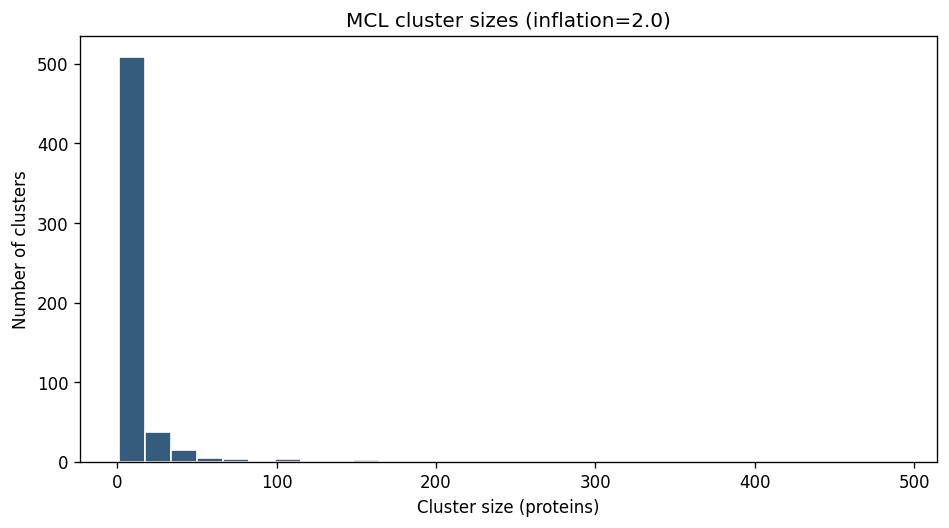

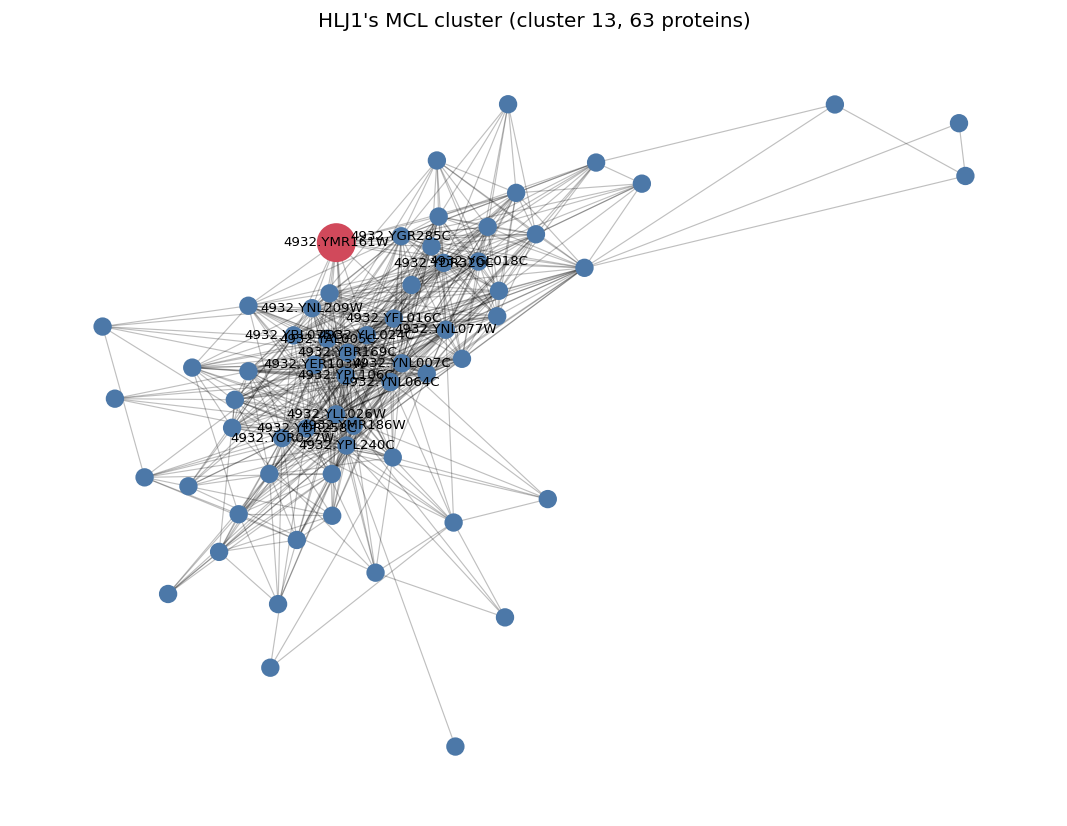

In [1]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist([len(c) for c in clusters], bins=30, color="#355C7D", edgecolor="white")
ax.set_xlabel("Cluster size (proteins)")
ax.set_ylabel("Number of clusters")
ax.set_title(f"MCL cluster sizes (inflation={INFLATION})")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "mcl_cluster_size_distribution.png", dpi=200)
plt.show()

H = G.subgraph(clusters[HLJ1_CLUSTER_ID - 1]).copy()
plt.figure(figsize=(9, 7))
pos = nx.spring_layout(H, seed=42, weight="weight")
node_colors = ["#D1495B" if n == HLJ1_NODE else "#4C78A8" for n in H.nodes]
node_sizes = [500 if n == HLJ1_NODE else 100 for n in H.nodes]
nx.draw_networkx_edges(H, pos, alpha=0.25, width=0.7)
nx.draw_networkx_nodes(H, pos, node_color=node_colors, node_size=node_sizes)
labels = {n: n for n in H.nodes if n == HLJ1_NODE or H.degree(n) >= max(2, int(np.percentile([d for _, d in H.degree()], 75)))}
nx.draw_networkx_labels(H, pos, labels=labels, font_size=8)
plt.title(f"HLJ1's MCL cluster (cluster {HLJ1_CLUSTER_ID}, {len(H)} proteins)")
plt.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "hlj1_mcl_cluster.png", dpi=200)
plt.show()


## 9. Interpretation and reporting notes

When writing up the result, report the input dataset and version, interaction type, confidence threshold, graph size after filtering, whether the largest/HLJ1-containing component was analysed, MCL implementation, inflation parameter, and sensitivity results. Describe proteins as **network-based candidates** or **members of HLJ1's MCL cluster**, not as confirmed biological targets.

Before submitting this notebook:

1. Add the real STRING input file (or document where it is stored).
2. Run the notebook from top to bottom and resolve any errors.
3. Check that the printed graph sizes and output tables match the team's final analysis.
4. Save the executed notebook so the outputs and figures are visible.
5. Upload the `.ipynb` to the repository's `notebook/` folder.
